# Phase 1 — Efficient Transformer (Llama style)

Modern efficient decoder-only design: **RoPE** rotary positions instead of
absolute embeddings, **grouped-query attention** (12 query heads sharing 4 KV heads),
**SwiGLU** feed-forward and **RMSNorm**. GQA cuts the KV cache 3x at generation time,
which matters when every test prompt is ~700-900 tokens.

**Everything is hand-implemented** — model, positional scheme, attention masks, KV-cached generation and the training loop. Nothing is imported from `transformers`; the tokenizer is the from-scratch BPE (`bpe_tokenizer.py`) from the prep notebook.

**Prerequisite:** run `00_prep_tokenizer_and_data.ipynb` first and attach its output as a
Kaggle Dataset input. This notebook never tokenizes anything — it memory-maps the token
stream that notebook produced.

**Architecture note:** `num_key_value_heads` must divide `num_attention_heads`. fp16 is safe.

Target size: ~125M parameters (inside the 50M-300M rule, in the recommended 100M-150M band).
All four notebooks share identical data, tokenizer, context length, optimizer, schedule and
seed, so any difference in final score is attributable to the architecture.

In [1]:
!pip install -q ijson rouge-score sacrebleu bert-score
print("deps ok")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 6.8 MB/s eta 0:00:00
deps ok


## 1. Hugging Face login

Two tokens are used. The **read** token (`HF`) downloads the gated dataset. The **write**
token (`HF_WRITE`) pushes training checkpoints to your own Hub repo so a killed Kaggle
session is resumable. Create the write token at *huggingface.co → Settings → Access
Tokens → role "Write"* and add it as a Kaggle secret named `HF_WRITE`.


In [2]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")               # read scope: dataset download
try:
    HF_WRITE_TOKEN = user_secrets.get_secret("HF_WRITE")   # write scope: checkpoint push
except Exception:
    HF_WRITE_TOKEN = None
    print("WARNING: no HF_WRITE secret found. Hub checkpointing will be disabled, so a "
          "session crash loses everything not on local disk. Add the secret and rerun "
          "if you want resumable training.")

os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("logged in | hub checkpointing:", bool(HF_WRITE_TOKEN))


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


logged in | hub checkpointing: True


## 2. GPU check (single device)

In [3]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU count     :", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name}  {p.total_memory/1e9:.1f} GB")

MULTI_GPU = torch.cuda.device_count() > 1
if MULTI_GPU:
    print("\n2 GPUs detected. The hand-written loop puts the model on cuda:0 only (no "
          "DataParallel wrapper), so runs stay single-GPU and comparable across notebooks.")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

CUDA available: True
GPU count     : 2
  GPU 0: Tesla T4  15.6 GB
  GPU 1: Tesla T4  15.6 GB

2 GPUs detected. The hand-written loop puts the model on cuda:0 only (no DataParallel wrapper), so runs stay single-GPU and comparable across notebooks.


## 3. Configuration

`MODEL_CONTEXT_LENGTH` (2048) is the size of the position table / max sequence the model
accepts; `TRAIN_BLOCK_SIZE` (1024) is the training sequence length. They are decoupled, but
generation must stay where the model was actually trained: `GEN_CONTEXT` is the token budget
for prompt + continuation (prompt budget = `GEN_CONTEXT - MAX_GENERATION_TOKENS`, always
positive, so the truncation arithmetic can't go negative). A 128-word continuation is ~180
legal-BPE tokens; generation stops as soon as every row passes 128 words, so the
`MAX_GENERATION_TOKENS` cap rarely binds.

In [4]:
import json, math, random, time, glob, zipfile, shutil
from pathlib import Path
import numpy as np

ARCH_NAME = "llamastyle"
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- locate the prep dataset --------------------------------------------------
cands = [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/meta.json", recursive=True)
         if os.path.exists(os.path.join(os.path.dirname(p), "train.bin"))]
DATA_DIR = cands[0] if cands else None
assert DATA_DIR, ("Could not find the prep dataset. Add the output of "
                  "00_prep_tokenizer_and_data.ipynb as a Kaggle Dataset input.")
if len(cands) > 1:
    print(f"WARNING: found {len(cands)} candidate data dirs, using the first: {DATA_DIR}")
print("data dir:", DATA_DIR)

META = json.load(open(os.path.join(DATA_DIR, "meta.json")))
VOCAB_SIZE = META["vocab_size"]
DTYPE = np.dtype(META["dtype"])
print(json.dumps(META, indent=2))

# ---- model / training ---------------------------------------------------------
MODEL_CONTEXT_LENGTH = 2048
TRAIN_BLOCK_SIZE = 1024

PER_DEVICE_BATCH = 4          # drop to 2 if you OOM
GRAD_ACCUM = 8                # effective batch = 4 x 8 x 1024 = 32,768 tokens/step
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1
WARMUP_STEPS = 500
MAX_STEPS = 12000             # ~390M tokens; the time budget below usually binds first
TRAIN_HOURS_BUDGET = 9.0      # stop cleanly before Kaggle's 12h wall
USE_FP16 = torch.cuda.is_available()

EVAL_STEPS = 1000
SAVE_STEPS = 500
LOGGING_STEPS = 50
SAVE_TOTAL_LIMIT = 2           # local checkpoints kept
EVAL_MAX_BLOCKS = 400          # val blocks per periodic eval (~0.4M tokens, ~1 min)
FINAL_EVAL_BLOCKS = 4000       # val blocks for the final perplexity (~4M tokens)

# ---- generation ---------------------------------------------------------------
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 288   # cap; generation stops early once every row has >128 words
GEN_CONTEXT = TRAIN_BLOCK_SIZE   # prompt + output budget: RoPE doesn't extrapolate reliably past the trained length
GENERATION_BATCH_SIZE = 8

# ---- hub / output -------------------------------------------------------------
HF_USERNAME = "rudra5972"     # <<< set this to your Hugging Face username
HUB_MODEL_ID = f"{HF_USERNAME}/legal-lm-phase1-{ARCH_NAME}"
RESUME = False                # flip True to continue a killed run

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

OUTPUT_DIR = f"/kaggle/working/phase1_{ARCH_NAME}"
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
FINAL_DIR = os.path.join(OUTPUT_DIR, "final")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss_curve.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert GEN_CONTEXT <= MODEL_CONTEXT_LENGTH and GEN_CONTEXT - MAX_GENERATION_TOKENS > 0
print(f"\narch {ARCH_NAME} | prompt budget {GEN_CONTEXT - MAX_GENERATION_TOKENS} tokens")

data dir: /kaggle/input/datasets/rudraadave5972/cs781-phase1-data
{
  "vocab_size": 32000,
  "dtype": "uint16",
  "n_train_tokens": 4180580316,
  "n_val_tokens": 41975396,
  "n_documents_streamed": 3480220,
  "n_holdout_pairs": 47,
  "source_files": [
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
    "Phase_1_Pretraining/Train/train_high_courts.json"
  ],
  "seed": 42,
  "prompt_words": 512,
  "continuation_words": 128,
  "eos_token_id": 0,
  "pad_token_id": 1,
  "ln_vocab_size": 10.373491181781864
}

arch llamastyle | prompt budget 736 tokens


## 4. Tokenizer


In [5]:
import sys
# The prep notebook wrote bpe_tokenizer.py + bpe_model.json next to the data: a from-scratch
# byte-level BPE (pure Python). No tokenizer library, no transformers.
if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)
from bpe_tokenizer import BPETokenizer

tokenizer = BPETokenizer.from_pretrained(DATA_DIR)
tokenizer.padding_side = "left"        # required for correct batched decoder-only generation
tokenizer.truncation_side = "left"     # an over-long prompt must lose its start, not its end

assert len(tokenizer) == VOCAB_SIZE, f"tokenizer vocab {len(tokenizer)} != meta.json {VOCAB_SIZE}"
assert tokenizer.eos_token_id == META["eos_token_id"] and tokenizer.pad_token_id == META["pad_token_id"]
_rt = "The appellant filed a writ petition under Article 226 of the Constitution."
assert tokenizer.decode(tokenizer.encode(_rt)) == _rt, "tokenizer round trip failed"

LN_VOCAB = META.get("ln_vocab_size", math.log(len(tokenizer)))
print("vocab            :", len(tokenizer))
print("pad / eos ids    :", tokenizer.pad_token_id, tokenizer.eos_token_id)
print("padding side     :", tokenizer.padding_side, "| truncation side:", tokenizer.truncation_side)
print("ln(vocab_size)   :", f"{LN_VOCAB:.4f}   <- a healthy model starts here and goes down")

vocab            : 32000
pad / eos ids    : 1 0
padding side     : left | truncation side: left
ln(vocab_size)   : 10.3735   <- a healthy model starts here and goes down


## 5. Memory-mapped token dataset

No tokenization, no `json.load`, no growing Python lists. `__getitem__` slices a
memory-mapped `uint16` array, so a block costs a few microseconds and RAM stays flat no
matter how large the corpus is. The memmap is opened lazily so DataLoader workers each
get their own handle instead of inheriting one across `fork`.


In [6]:
from torch.utils.data import Dataset

class MemmapBlockDataset(Dataset):
    def __init__(self, path, block_size, dtype=np.uint16):
        self.path, self.block_size, self.dtype = str(path), block_size, dtype
        self.n_tokens = os.path.getsize(self.path) // np.dtype(dtype).itemsize
        self.n_blocks = max(0, (self.n_tokens - 1) // block_size)
        self._arr = None

    @property
    def arr(self):
        if self._arr is None:                      # lazy: one handle per worker process
            self._arr = np.memmap(self.path, dtype=self.dtype, mode="r")
        return self._arr

    def __len__(self):
        return self.n_blocks

    def __getitem__(self, i):
        s = i * self.block_size
        x = torch.from_numpy(self.arr[s:s + self.block_size].astype(np.int64))
        return {"input_ids": x, "labels": x.clone()}

train_dataset = MemmapBlockDataset(os.path.join(DATA_DIR, "train.bin"), TRAIN_BLOCK_SIZE, DTYPE)
val_dataset   = MemmapBlockDataset(os.path.join(DATA_DIR, "val.bin"),   TRAIN_BLOCK_SIZE, DTYPE)

print(f"train: {len(train_dataset):,} blocks  ({train_dataset.n_tokens:,} tokens)")
print(f"val  : {len(val_dataset):,} blocks  ({val_dataset.n_tokens:,} tokens)")

_b = train_dataset[0]["input_ids"]
assert int(_b.max()) < VOCAB_SIZE, "token id outside vocab -- tokenizer/corpus mismatch"
print("sample block:", tuple(_b.shape), "| decoded:", tokenizer.decode(_b[:40].tolist())[:180])

tokens_per_step = PER_DEVICE_BATCH * GRAD_ACCUM * TRAIN_BLOCK_SIZE
print(f"\n{tokens_per_step:,} tokens/optimizer step | {MAX_STEPS} steps = "
      f"{tokens_per_step*MAX_STEPS/1e6:.0f}M tokens "
      f"({tokens_per_step*MAX_STEPS/train_dataset.n_tokens:.2f} epochs)")


train: 4,082,597 blocks  (4,180,580,316 tokens)
val  : 40,991 blocks  (41,975,396 tokens)
sample block: (1024,) | decoded: Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act No. 2 of 1996) Statements of objects and Reasons - Act 2 of 1996. - The Bangalore

32,768 tokens/optimizer step | 12000 steps = 393M tokens (0.09 epochs)


## 6. Build the model — hand-implemented, randomly initialised

No model class from any library. The only things used from PyTorch are generic layer
primitives (`nn.Embedding`, `nn.Linear`, `nn.LayerNorm`) and the fused attention kernel
`F.scaled_dot_product_attention`. Everything that defines the architecture — block
layout, positional scheme, head splitting, masks, KV cache, generation — is below.

### 6a. Shared core (identical in all four notebooks)

* `CausalLMOutput` — `.loss`, `.logits`, `.past_key_values`, so the rest of the pipeline is unchanged.
* `positions_from_mask` — with **left padding**, a token's position is its index among
  the real tokens (cumsum of the attention mask), not its column index.
* `causal_allowed` / `build_attn_mask` — the boolean "who may attend to whom" matrix:
  causal, optional sliding window, padding keys removed. When nothing but plain causality
  is needed it returns `None` so SDPA can use its fastest `is_causal=True` kernel.
* `init_weights` — N(0, 0.02) on every Linear/Embedding, residual output projections
  scaled by 1/sqrt(2·n_layer) (GPT-2 recipe) so the residual stream doesn't grow with depth.
* `CausalLMBase.generate` — KV-cached greedy / sampling (temperature, top-p, top-k) /
  beam search, repetition penalty, no-repeat-n-gram, token suppression, early stop.

In [7]:
import math
from dataclasses import dataclass, asdict, field
from typing import Optional, List, Tuple
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from numpy.lib.stride_tricks import sliding_window_view


@dataclass
class CausalLMOutput:
    loss: Optional[torch.Tensor] = None
    logits: Optional[torch.Tensor] = None
    past_key_values: Optional[list] = None      # per layer: (k, v), each (B, n_kv_heads, S, head_dim)


def positions_from_mask(attention_mask, past_len, T, B, device):
    """Position ids for the T new tokens. attention_mask (if given) covers ALL keys: (B, past_len+T)."""
    if attention_mask is None:
        return torch.arange(past_len, past_len + T, device=device).unsqueeze(0).expand(B, T)
    pos = (attention_mask.long().cumsum(-1) - 1).clamp(min=0)
    return pos[:, -T:]


def causal_allowed(T, past_len, attention_mask, window, device):
    """Bool (B|1, 1, T, S): True where query t may attend key s. Always materialised."""
    S = past_len + T
    q = torch.arange(past_len, S, device=device)[:, None]      # absolute index of each query
    k = torch.arange(S, device=device)[None, :]
    allowed = k <= q                                             # causal
    if window is not None:
        allowed = allowed & (q - k < window)                     # sliding window: last `window` keys incl. self
    allowed = allowed[None, None]
    if attention_mask is not None:
        allowed = allowed & attention_mask[:, None, None, :].bool()   # drop padding keys
        allowed = allowed | (q == k)[None, None]                 # a pad query would see nothing -> NaN; let it see itself
    return allowed


def build_attn_mask(T, past_len, attention_mask, window, device):
    """Returns (mask, is_causal) for F.scaled_dot_product_attention."""
    S = past_len + T
    window_active = window is not None and window < S
    no_pad = attention_mask is None or bool(attention_mask.all())
    if no_pad and not window_active:
        if past_len == 0:
            return None, True        # fast fused causal kernel (training path)
        if T == 1:
            return None, False       # single cached query sees every key
    return causal_allowed(T, past_len, None if no_pad else attention_mask,
                          window if window_active else None, device), False


def init_weights(model, n_layer, std=0.02):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=std)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=std)
    for name, p in model.named_parameters():       # residual-branch output projections
        if name.endswith("o_proj.weight") or name.endswith("down_proj.weight"):
            nn.init.normal_(p, mean=0.0, std=std / math.sqrt(2 * n_layer))


# ------------------------------------------------------------------ decoding helpers
def _sample(logits, temperature, top_p, top_k):
    logits = logits / max(float(temperature), 1e-5)
    if top_k and top_k > 0:
        kth = torch.topk(logits, min(int(top_k), logits.size(-1)), dim=-1).values[:, -1:]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if top_p is not None and top_p < 1.0:
        sl, si = torch.sort(logits, descending=True, dim=-1)
        probs = sl.softmax(-1)
        remove = probs.cumsum(-1) - probs > top_p           # keep the smallest set with mass >= top_p
        sl = sl.masked_fill(remove, float("-inf"))
        logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
    return torch.multinomial(logits.softmax(-1), 1).squeeze(1)


def _banned_ngram_tokens(row, n):
    """Tokens that would complete an n-gram already present in `row` (list of ints)."""
    if n < 2 or len(row) < n:
        return []
    arr = np.asarray(row)
    win = sliding_window_view(arr[:-1], n - 1)           # window i = arr[i:i+n-1], followed by arr[i+n-1]
    hit = np.nonzero((win == arr[-(n - 1):]).all(1))[0]
    return arr[hit + n - 1].tolist()


class CausalLMBase(nn.Module):
    """Loss + generation shared by all four architectures."""

    @staticmethod
    def lm_loss(logits, labels):
        return F.cross_entropy(logits[:, :-1].reshape(-1, logits.size(-1)).float(),
                               labels[:, 1:].reshape(-1), ignore_index=-100)

    def _process_logits(self, logits, seq, rows, repetition_penalty, no_repeat_ngram_size, suppress):
        if repetition_penalty and repetition_penalty != 1.0:
            sc = torch.gather(logits, 1, seq)
            sc = torch.where(sc > 0, sc / repetition_penalty, sc * repetition_penalty)
            logits = logits.scatter(1, seq, sc)
        if no_repeat_ngram_size and no_repeat_ngram_size > 1:
            for b, row in enumerate(rows):
                banned = _banned_ngram_tokens(row, no_repeat_ngram_size)
                if banned:
                    logits[b, banned] = float("-inf")
        if suppress:
            logits[:, list(suppress)] = float("-inf")
        return logits

    @torch.inference_mode()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=256, do_sample=False,
                 temperature=1.0, top_p=1.0, top_k=0, repetition_penalty=1.0,
                 no_repeat_ngram_size=0, num_beams=1, suppress_token_ids=(),
                 stop_fn=None, stop_check_every=16, **_ignored):
        """Returns ONLY the new tokens, shape (B, n_new). stop_fn(new_tokens) -> True ends early."""
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)
        attention_mask = attention_mask.long()
        rows = [ids[m.bool()].tolist() for ids, m in zip(input_ids, attention_mask)]   # real tokens only
        if num_beams > 1:
            return self._beam_search(input_ids, attention_mask, rows, max_new_tokens, num_beams,
                                     repetition_penalty, no_repeat_ngram_size, suppress_token_ids,
                                     stop_fn, stop_check_every)
        out = self(input_ids, attention_mask=attention_mask, use_cache=True, last_only=True)
        past, logits = out.past_key_values, out.logits[:, -1].float()
        seq, new = input_ids, []
        for step in range(max_new_tokens):
            logits = self._process_logits(logits, seq, rows, repetition_penalty,
                                          no_repeat_ngram_size, suppress_token_ids)
            nxt = _sample(logits, temperature, top_p, top_k) if do_sample else logits.argmax(-1)
            new.append(nxt)
            seq = torch.cat([seq, nxt[:, None]], 1)
            attention_mask = torch.cat([attention_mask, torch.ones_like(nxt)[:, None]], 1)
            for row, t in zip(rows, nxt.tolist()):
                row.append(t)
            if step == max_new_tokens - 1:
                break
            if stop_fn is not None and (step + 1) % stop_check_every == 0 and stop_fn(torch.stack(new, 1)):
                break
            out = self(nxt[:, None], attention_mask=attention_mask, past_key_values=past, use_cache=True)
            past, logits = out.past_key_values, out.logits[:, -1].float()
        return torch.stack(new, 1)

    def _beam_search(self, input_ids, attention_mask, rows, max_new_tokens, K, repetition_penalty,
                     no_repeat_ngram_size, suppress, stop_fn, stop_check_every):
        B = input_ids.size(0)
        out = self(input_ids, attention_mask=attention_mask, use_cache=True, last_only=True)
        past = [(k.repeat_interleave(K, 0), v.repeat_interleave(K, 0)) for k, v in out.past_key_values]
        logits = out.logits[:, -1].float().repeat_interleave(K, 0)
        seq = input_ids.repeat_interleave(K, 0)
        am = attention_mask.repeat_interleave(K, 0)
        rows = [list(r) for r in rows for _ in range(K)]
        scores = torch.zeros(B, K, device=input_ids.device)
        scores[:, 1:] = -1e9                       # all beams start identical: expand from beam 0 only
        gen = seq[:, :0]
        for step in range(max_new_tokens):
            logits = self._process_logits(logits, seq, rows, repetition_penalty, no_repeat_ngram_size, suppress)
            logp = logits.log_softmax(-1)
            V = logp.size(-1)
            cand = (scores.view(-1, 1) + logp).view(B, K * V)
            top, idx = cand.topk(K, dim=1)
            src = (torch.arange(B, device=idx.device)[:, None] * K + idx // V).view(-1)
            tok = (idx % V).view(-1)
            scores = top
            gen = torch.cat([gen[src], tok[:, None]], 1)
            seq = torch.cat([seq[src], tok[:, None]], 1)
            am = torch.cat([am[src], torch.ones_like(tok)[:, None]], 1)
            rows = [rows[i] + [t] for i, t in zip(src.tolist(), tok.tolist())]
            past = [(k[src], v[src]) for k, v in past]
            if step == max_new_tokens - 1:
                break
            if stop_fn is not None and (step + 1) % stop_check_every == 0 and stop_fn(gen):
                break
            out = self(tok[:, None], attention_mask=am, past_key_values=past, use_cache=True)
            past, logits = out.past_key_values, out.logits[:, -1].float()
        best = scores.argmax(1)
        return gen.view(B, K, -1)[torch.arange(B, device=best.device), best]

print("shared model core defined")

shared model core defined


### 6b. Efficient transformer, Llama style

```
tokens ─► embed ─► [ x + GQA(RMSNorm(x), RoPE) ; x + SwiGLU(RMSNorm(x)) ] × 12 ─► RMSNorm ─► embedᵀ (tied)
```
* **RoPE:** no position table. Q and K are rotated pair-wise by an angle `pos · θ^(-2i/d)`:
  `x·cos + rotate_half(x)·sin`, where `rotate_half([x1, x2]) = [-x2, x1]`. The dot product
  q·k then depends only on the *relative* offset between the two positions.
* **Grouped-query attention:** 12 query heads, 4 K/V heads. Each K/V head is shared by 3
  consecutive query heads (`repeat_interleave` along the head axis right before SDPA); the
  KV cache stores only the 4 heads, 3× smaller.
* **RMSNorm** (no mean-centering, no bias, computed in fp32) and **SwiGLU**
  `down(silu(gate(x)) · up(x))`, 768 → 3072 → 768, no biases anywhere, tied embeddings.

In [8]:
@dataclass
class LlamaStyleConfig:
    vocab_size: int
    max_position_embeddings: int = 2048
    hidden_size: int = 768
    intermediate_size: int = 3072
    num_hidden_layers: int = 12
    num_attention_heads: int = 12
    num_key_value_heads: int = 4
    rope_theta: float = 10000.0
    rms_norm_eps: float = 1e-5
    sliding_window: Optional[int] = None      # None = full causal attention
    initializer_range: float = 0.02


class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).to(x.dtype)


class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, theta=10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2, dtype=torch.float32) / head_dim))
        self.register_buffer("inv_freq", inv_freq, persistent=False)

    def forward(self, pos):                                   # pos: (B, T) int
        freqs = pos[..., None].float() * self.inv_freq        # (B, T, hd/2)
        emb = torch.cat([freqs, freqs], dim=-1)               # (B, T, hd): angle for dim i and i+hd/2
        return emb.cos()[:, None], emb.sin()[:, None]         # (B, 1, T, hd) -> broadcast over heads


def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat([-x2, x1], dim=-1)


def apply_rope(x, cos, sin):
    return (x * cos + rotate_half(x) * sin).to(x.dtype)


class GQAttention(nn.Module):
    def __init__(self, c):
        super().__init__()
        assert c.hidden_size % c.num_attention_heads == 0
        assert c.num_attention_heads % c.num_key_value_heads == 0, "KV heads must divide query heads"
        self.h, self.kv = c.num_attention_heads, c.num_key_value_heads
        self.hd = c.hidden_size // c.num_attention_heads
        self.n_rep = self.h // self.kv
        self.q_proj = nn.Linear(c.hidden_size, self.h * self.hd, bias=False)
        self.k_proj = nn.Linear(c.hidden_size, self.kv * self.hd, bias=False)
        self.v_proj = nn.Linear(c.hidden_size, self.kv * self.hd, bias=False)
        self.o_proj = nn.Linear(self.h * self.hd, c.hidden_size, bias=False)

    def forward(self, x, cos, sin, mask, is_causal, past=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.h, self.hd).transpose(1, 2)    # (B, 12, T, hd)
        k = self.k_proj(x).view(B, T, self.kv, self.hd).transpose(1, 2)   # (B,  4, T, hd)
        v = self.v_proj(x).view(B, T, self.kv, self.hd).transpose(1, 2)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)           # rotate Q and K only
        if past is not None:
            k, v = torch.cat([past[0], k], 2), torch.cat([past[1], v], 2)
        present = (k, v)                                                  # cache stays at 4 heads
        if self.n_rep > 1:                                                # kv head j serves q heads j*3..j*3+2
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=is_causal)
        return self.o_proj(y.transpose(1, 2).reshape(B, T, self.h * self.hd)), present


class SwiGLU(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.gate_proj = nn.Linear(d, hidden, bias=False)
        self.up_proj = nn.Linear(d, hidden, bias=False)
        self.down_proj = nn.Linear(hidden, d, bias=False)

    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))


class LlamaBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.input_norm = RMSNorm(c.hidden_size, c.rms_norm_eps)
        self.attn = GQAttention(c)
        self.post_attn_norm = RMSNorm(c.hidden_size, c.rms_norm_eps)
        self.mlp = SwiGLU(c.hidden_size, c.intermediate_size)

    def forward(self, x, cos, sin, mask, is_causal, past=None):
        a, present = self.attn(self.input_norm(x), cos, sin, mask, is_causal, past)
        x = x + a
        x = x + self.mlp(self.post_attn_norm(x))
        return x, present


class LlamaStyleLM(CausalLMBase):
    def __init__(self, c):
        super().__init__()
        self.config = c
        self.embed_tokens = nn.Embedding(c.vocab_size, c.hidden_size)
        self.rotary = RotaryEmbedding(c.hidden_size // c.num_attention_heads, c.rope_theta)
        self.layers = nn.ModuleList([LlamaBlock(c) for _ in range(c.num_hidden_layers)])
        self.norm = RMSNorm(c.hidden_size, c.rms_norm_eps)
        self.lm_head = nn.Linear(c.hidden_size, c.vocab_size, bias=False)
        init_weights(self, c.num_hidden_layers, c.initializer_range)
        self.lm_head.weight = self.embed_tokens.weight

    def get_input_embeddings(self):
        return self.embed_tokens

    def forward(self, input_ids, labels=None, attention_mask=None, past_key_values=None,
                use_cache=False, last_only=False):
        B, T = input_ids.shape
        past_len = past_key_values[0][0].size(2) if past_key_values else 0
        pos = positions_from_mask(attention_mask, past_len, T, B, input_ids.device)
        cos, sin = self.rotary(pos)
        mask, is_causal = build_attn_mask(T, past_len, attention_mask,
                                          self.config.sliding_window, input_ids.device)
        x = self.embed_tokens(input_ids)
        presents = []
        for i, layer in enumerate(self.layers):
            x, pr = layer(x, cos, sin, mask, is_causal, past_key_values[i] if past_key_values else None)
            presents.append(pr)
        x = self.norm(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = self.lm_loss(logits, labels) if labels is not None else None
        return CausalLMOutput(loss=loss, logits=logits, past_key_values=presents if use_cache else None)


MODEL_CLASS, CONFIG_CLASS = LlamaStyleLM, LlamaStyleConfig
config = LlamaStyleConfig(vocab_size=VOCAB_SIZE, max_position_embeddings=MODEL_CONTEXT_LENGTH,
                          hidden_size=768, intermediate_size=3072, num_hidden_layers=12,
                          num_attention_heads=12, num_key_value_heads=4, sliding_window=None)

torch.manual_seed(SEED)
model = MODEL_CLASS(config)                    # random init, trained from scratch

n_params = sum(p.numel() for p in model.parameters())          # tied weight counted once
n_emb = model.get_input_embeddings().weight.numel()
print(type(model).__name__, json.dumps(asdict(config)))
print(f"total parameters     : {n_params/1e6:.2f}M")
print(f"  embedding (tied)   : {n_emb/1e6:.2f}M")
print(f"  non-embedding      : {(n_params-n_emb)/1e6:.2f}M")
assert 50e6 <= n_params <= 300e6, "outside the 50M-300M competition rule"
if not (100e6 <= n_params <= 150e6):
    print("NOTE: outside the recommended 100M-150M band -- allowed, but adjust if unintended.")

LlamaStyleLM {"vocab_size": 32000, "max_position_embeddings": 2048, "hidden_size": 768, "intermediate_size": 3072, "num_hidden_layers": 12, "num_attention_heads": 12, "num_key_value_heads": 4, "rope_theta": 10000.0, "rms_norm_eps": 1e-05, "sliding_window": null, "initializer_range": 0.02}
total parameters     : 128.40M
  embedding (tied)   : 24.58M
  non-embedding      : 103.83M


### Correctness tests of the hand-written model

Run on a tiny copy of the same class (CPU, fp32, a few seconds). These catch the bugs a
custom implementation actually has — a model can train to a fine loss and still generate
garbage if the KV cache or padding logic is wrong:

1. **causality** — changing token *t* must not change logits at positions < *t*;
2. **KV cache** — prompt + token-by-token cached decoding must equal one full forward;
3. **left padding** — a padded row must give the same logits as the same prompt unpadded;
4. architecture-specific check (see printout).

In [9]:
def _tiny(**over):
    torch.manual_seed(0)
    return MODEL_CLASS(CONFIG_CLASS(**{**TINY, **over})).eval()

def run_model_tests():
    m = _tiny()
    V = TINY["vocab_size"]
    a = torch.randint(3, V, (1, 40))
    with torch.no_grad():
        full = m(a).logits
        # 1. causality
        b = a.clone(); b[0, 25] = (b[0, 25] + 1 - 3) % (V - 3) + 3
        d = (m(b).logits - full).abs().amax(-1)[0]
        assert d[:25].max() < 1e-5, "future token leaked into the past"
        assert d[25:].max() > 1e-6
        # 2. KV cache
        out = m(a[:, :30], use_cache=True)
        past, steps = out.past_key_values, [out.logits[:, -1]]
        for t in range(30, 40):
            o = m(a[:, t:t + 1], past_key_values=past, use_cache=True)
            past = o.past_key_values; steps.append(o.logits[:, -1])
        cached = torch.stack(steps[:-1], 1)
        assert (cached - full[:, 29:39]).abs().max() < 1e-4, "KV-cache decoding != full forward"
        # 3. left padding (batch of a padded short row + a full row)
        short = a[:, 10:]
        batch = torch.cat([torch.cat([torch.full((1, 10), 1), short], 1), a], 0)
        am = torch.cat([torch.cat([torch.zeros(1, 10), torch.ones(1, 30)], 1), torch.ones(1, 40)], 0).long()
        pl = m(batch, attention_mask=am).logits
        ref = m(short).logits
        assert (pl[0, 10:] - ref[0]).abs().max() < 1e-4, "left padding changes the result"
        assert (pl[1] - full[0]).abs().max() < 1e-4
        # padded + cached generation == unpadded generation
        g1 = m.generate(batch, attention_mask=am, max_new_tokens=8)
        g2 = m.generate(short, max_new_tokens=8)
        assert torch.equal(g1[0], g2[0]), "padded batched generation differs from single-row generation"
    print("causality ok | KV cache ok | left padding ok | padded generation ok")
    arch_specific_test()

TINY = dict(vocab_size=97, max_position_embeddings=128, hidden_size=64, intermediate_size=128,
            num_hidden_layers=2, num_attention_heads=4, num_key_value_heads=2)

def arch_specific_test():
    # RoPE: q.k after rotation depends only on the relative offset
    rot = RotaryEmbedding(16)
    q, k = torch.randn(1, 1, 1, 16), torch.randn(1, 1, 1, 16)
    def score(pq, pk):
        cq, sq = rot(torch.tensor([[pq]])); ck, sk = rot(torch.tensor([[pk]]))
        return (apply_rope(q, cq, sq) * apply_rope(k, ck, sk)).sum().item()
    assert abs(score(5, 2) - score(105, 102)) < 1e-4, "RoPE is not relative"
    # GQA really shares K/V: projection widths
    m = _tiny()
    att = m.layers[0].attn
    assert att.k_proj.out_features == TINY["num_key_value_heads"] * att.hd
    print("RoPE relative-position property ok | GQA K/V width ok ("
          f"{TINY['num_attention_heads']} q heads / {TINY['num_key_value_heads']} kv heads)")

run_model_tests()

causality ok | KV cache ok | left padding ok | padded generation ok
RoPE relative-position property ok | GQA K/V width ok (4 q heads / 2 kv heads)


### Initialization sanity check

A correctly initialised LM starts at roughly `ln(vocab_size)` — it is predicting a near
uniform distribution. If the first loss is far above that, the problem is the
initialization, not the architecture, and a short run will never recover.


In [10]:
model.eval()
with torch.no_grad():
    _x = torch.stack([train_dataset[i]["input_ids"] for i in range(2)])
    _init_loss = model(input_ids=_x, labels=_x).loss.item()
model.train()
print(f"loss at init : {_init_loss:.4f}")
print(f"ln(vocab)    : {LN_VOCAB:.4f}")
print(f"ratio        : {_init_loss/LN_VOCAB:.3f}")
if _init_loss > LN_VOCAB + 0.8:
    print("\nWARNING: init loss is well above ln(V). Check weight init before training.")
else:
    print("\ninit looks healthy.")


loss at init : 10.5771
ln(vocab)    : 10.3735
ratio        : 1.020

init looks healthy.


## 7. Training loop setup (hand-written, no `Trainer`)

Everything `Trainer` used to do, written out so nothing comes from `transformers`:

* **AdamW** (β = 0.9/0.95, weight decay only on ≥2-D weights), **linear warmup → cosine** LR,
  **fp16 autocast + GradScaler**, gradient accumulation, grad-norm clipping at 1.0.
* **Data order:** a fixed seeded permutation of all train blocks. Resuming at step *s* simply
  starts at sample `s × batch × accum` — exact, instant, no re-reading skipped batches.
* **Checkpoints** (`checkpoint-<step>/`: weights, optimizer, scheduler, scaler, RNG state,
  log history) go to **local disk** every `SAVE_STEPS`, last `SAVE_TOTAL_LIMIT` kept, and each
  one is uploaded in a background thread to `last-checkpoint/` in your **private Hub repo**
  with the write token. A dead session loses at most `SAVE_STEPS` steps.
* **Single device by construction:** the model lives on `cuda:0`; there is no DataParallel
  wrapper to break anything, even when Kaggle gives two GPUs.

In [11]:
import inspect, contextlib, threading
from torch.utils.data import DataLoader, Dataset
from huggingface_hub import create_repo, upload_folder, snapshot_download

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

if torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8:
    AMP_DTYPE = torch.bfloat16                        # Ampere+: bf16, no loss scaling needed
elif USE_FP16:
    AMP_DTYPE = torch.float16                         # T4 / P100
else:
    AMP_DTYPE = None
USE_SCALER = AMP_DTYPE == torch.float16

def amp_ctx():
    if AMP_DTYPE is None or device.type != "cuda":
        return contextlib.nullcontext()
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE)

# ---- optimizer / schedule / scaler ---------------------------------------------
decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                               {"params": no_decay, "weight_decay": 0.0}],
                              lr=LEARNING_RATE, betas=(0.9, 0.95), eps=1e-8)

def lr_lambda(step):                                   # linear warmup -> cosine to 0
    if step < WARMUP_STEPS:
        return step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_SCALER)

# ---- deterministic, resumable data order ----------------------------------------
SAMPLES_PER_STEP = PER_DEVICE_BATCH * GRAD_ACCUM
PERM = np.random.default_rng(SEED).permutation(len(train_dataset))

class OrderedBlocks(Dataset):
    """Samples PERM[start], PERM[start+1], ... (wrapping) up to `end`."""
    def __init__(self, base, perm, start, end):
        self.base, self.perm, self.start, self.end = base, perm, start, end
    def __len__(self):
        return max(0, self.end - self.start)
    def __getitem__(self, i):
        return self.base[int(self.perm[(self.start + i) % len(self.perm)])]

def make_loader(start_step):
    ds = OrderedBlocks(train_dataset, PERM, start_step * SAMPLES_PER_STEP, MAX_STEPS * SAMPLES_PER_STEP)
    return DataLoader(ds, batch_size=PER_DEVICE_BATCH, shuffle=False, drop_last=True,
                      num_workers=2, pin_memory=torch.cuda.is_available())

# ---- evaluation -------------------------------------------------------------------
@torch.no_grad()
def evaluate(max_blocks=EVAL_MAX_BLOCKS):
    """Mean loss over evenly spaced val blocks (val.bin is ordered by source)."""
    was_training = model.training
    model.eval()
    idx = np.linspace(0, len(val_dataset) - 1, min(max_blocks, len(val_dataset))).astype(int)
    tot, n = 0.0, 0
    for s in range(0, len(idx), PER_DEVICE_BATCH):
        x = torch.stack([val_dataset[int(i)]["input_ids"] for i in idx[s:s + PER_DEVICE_BATCH]]).to(device)
        with amp_ctx():
            loss = model(x, labels=x).loss
        tot += loss.item() * x.size(0); n += x.size(0)
    model.train(was_training)
    return tot / max(1, n)

# ---- checkpointing: local disk + Hub --------------------------------------------
HUB_ENABLED = bool(HF_WRITE_TOKEN) and HF_USERNAME != "CHANGE_ME"
_push = {"future": None}

def _wait_for_push():
    f = _push["future"]
    if f is not None:
        try:
            f.result()
        except Exception as e:
            print("   [hub] previous push failed (local copy is safe):", e)
        _push["future"] = None

def push_checkpoint_async(path, step):
    if not HUB_ENABLED:
        return
    _wait_for_push()                                   # at most one upload in flight
    try:
        _push["future"] = upload_folder(repo_id=HUB_MODEL_ID, folder_path=path,
                                        path_in_repo="last-checkpoint", token=HF_WRITE_TOKEN,
                                        commit_message=f"{ARCH_NAME} checkpoint step {step}",
                                        delete_patterns=["*"], run_as_future=True)
    except Exception as e:
        print("   [hub] could not start push:", e)

def _rng_state():
    st = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if torch.cuda.is_available():
        st["cuda"] = torch.cuda.get_rng_state_all()
    return st

def save_checkpoint(step):
    path = os.path.join(MODEL_OUTPUT_DIR, f"checkpoint-{step}")
    tmp = path + ".tmp"
    shutil.rmtree(tmp, ignore_errors=True); os.makedirs(tmp)
    torch.save(model.state_dict(), os.path.join(tmp, "model.pt"))
    torch.save(optimizer.state_dict(), os.path.join(tmp, "optimizer.pt"))
    torch.save({"scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "rng": _rng_state()},
               os.path.join(tmp, "extra_state.pt"))
    json.dump({"global_step": step, "max_steps": MAX_STEPS, "arch": ARCH_NAME,
               "model_class": type(model).__name__, "config": asdict(config),
               "samples_per_step": SAMPLES_PER_STEP, "log_history": LOG_HISTORY},
              open(os.path.join(tmp, "trainer_state.json"), "w"))
    shutil.rmtree(path, ignore_errors=True); os.rename(tmp, path)        # atomic-ish: never a half-written ckpt
    ckpts = sorted(glob.glob(os.path.join(MODEL_OUTPUT_DIR, "checkpoint-*[0-9]")),
                   key=lambda p: int(p.rsplit("-", 1)[1]))
    for old in ckpts[:-SAVE_TOTAL_LIMIT]:
        shutil.rmtree(old, ignore_errors=True)
    push_checkpoint_async(path, step)
    print(f"   [ckpt] step {step} saved -> {path}" + (" (+ hub push)" if HUB_ENABLED else ""))

def load_checkpoint(path):
    model.load_state_dict(torch.load(os.path.join(path, "model.pt"), map_location=device))
    optimizer.load_state_dict(torch.load(os.path.join(path, "optimizer.pt"), map_location=device))
    extra = torch.load(os.path.join(path, "extra_state.pt"), map_location="cpu", weights_only=False)
    scheduler.load_state_dict(extra["scheduler"]); scaler.load_state_dict(extra["scaler"])
    rng = extra["rng"]
    random.setstate(rng["python"]); np.random.set_state(rng["numpy"]); torch.set_rng_state(rng["torch"])
    if "cuda" in rng and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(rng["cuda"])
    state = json.load(open(os.path.join(path, "trainer_state.json")))
    assert state["samples_per_step"] == SAMPLES_PER_STEP, "batch size changed since this checkpoint"
    return state["global_step"], state["log_history"]

def find_resume_checkpoint():
    if not RESUME:
        return None
    local = sorted(glob.glob(os.path.join(MODEL_OUTPUT_DIR, "checkpoint-*[0-9]")),
                   key=lambda p: int(p.rsplit("-", 1)[1]))
    if local:
        print("resuming from local checkpoint:", local[-1])
        return local[-1]
    if HUB_ENABLED:
        try:
            p = snapshot_download(repo_id=HUB_MODEL_ID, allow_patterns=["last-checkpoint/*"],
                                  token=HF_WRITE_TOKEN, local_dir=os.path.join(OUTPUT_DIR, "hub_ckpt"))
            cp = os.path.join(p, "last-checkpoint")
            if os.path.exists(os.path.join(cp, "trainer_state.json")):
                print("resuming from hub checkpoint:", cp)
                return cp
        except Exception as e:
            print("could not pull a hub checkpoint:", e)
    print("RESUME=True but no checkpoint found -- starting fresh.")
    return None

if HUB_ENABLED:
    create_repo(HUB_MODEL_ID, private=True, exist_ok=True, token=HF_WRITE_TOKEN)
    print("hub checkpointing ->", HUB_MODEL_ID, "(private)")
else:
    print("hub checkpointing DISABLED (set HF_USERNAME and the HF_WRITE secret to enable)")
print(f"device {device} | amp {AMP_DTYPE} | grad scaler {USE_SCALER} | "
      f"effective batch tokens: {tokens_per_step:,} | {MAX_STEPS} steps")

hub checkpointing -> rudra5972/legal-lm-phase1-llamastyle (private)
device cuda | amp torch.float16 | grad scaler True | effective batch tokens: 32,768 | 12000 steps


## 8. Train

Stops cleanly at `TRAIN_HOURS_BUDGET` or `MAX_STEPS`, always on a saved, resumable checkpoint.

In [12]:
LOG_HISTORY = []
start_step = 0
_resume = find_resume_checkpoint()
if _resume:
    start_step, LOG_HISTORY = load_checkpoint(_resume)
    print(f"continuing at step {start_step}/{MAX_STEPS}")

global_step = start_step
model.train()
optimizer.zero_grad(set_to_none=True)
t0 = time.time(); t_log = t0
run_loss = torch.zeros((), device=device); run_micro = 0; micro = 0
last_saved, stop_reason = start_step, None

try:
    for batch in make_loader(start_step):
        x = batch["input_ids"].to(device, non_blocking=True)
        with amp_ctx():
            loss = model(x, labels=x).loss
        scaler.scale(loss / GRAD_ACCUM).backward()
        run_loss += loss.detach(); run_micro += 1; micro += 1
        if micro % GRAD_ACCUM:
            continue

        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()
        global_step += 1

        if global_step % LOGGING_STEPS == 0 or global_step == start_step + 1:
            now = time.time()
            avg = (run_loss / run_micro).item()
            tps = run_micro * PER_DEVICE_BATCH * TRAIN_BLOCK_SIZE / (now - t_log)
            LOG_HISTORY.append({"step": global_step, "loss": avg, "learning_rate": scheduler.get_last_lr()[0],
                                "grad_norm": float(grad_norm)})
            print(f"step {global_step:>6}/{MAX_STEPS} | loss {avg:.4f} | lr {scheduler.get_last_lr()[0]:.2e} | "
                  f"gnorm {float(grad_norm):.2f} | {tps:,.0f} tok/s | {(now - t0)/3600:.2f} h", flush=True)
            if not math.isfinite(avg):
                raise RuntimeError("loss is NaN/inf -- lower LEARNING_RATE or check the model")
            run_loss.zero_(); run_micro = 0; t_log = now

        if global_step % EVAL_STEPS == 0:
            ev = evaluate()
            LOG_HISTORY.append({"step": global_step, "eval_loss": ev})
            print(f"   [eval] step {global_step} | val loss {ev:.4f} | ppl {math.exp(min(ev, 20)):.2f}")

        if global_step % SAVE_STEPS == 0:
            save_checkpoint(global_step); last_saved = global_step

        if time.time() - t0 > TRAIN_HOURS_BUDGET * 3600:
            stop_reason = f"time budget {TRAIN_HOURS_BUDGET}h"
            break
        if global_step >= MAX_STEPS:
            stop_reason = "MAX_STEPS"
            break
except torch.cuda.OutOfMemoryError:
    torch.cuda.empty_cache()
    raise RuntimeError("CUDA OOM. Halve PER_DEVICE_BATCH and double GRAD_ACCUM, then rerun "
                       "(RESUME=True keeps the progress already checkpointed).")

if global_step != last_saved:
    save_checkpoint(global_step)                     # always end on a resumable checkpoint
_wait_for_push()

train_seconds = time.time() - t0
done_steps = global_step
seen_tokens = done_steps * tokens_per_step
session_tokens = (done_steps - start_step) * tokens_per_step
print(f"\nstopped: {stop_reason or 'data exhausted'}")
print(f"trained {done_steps - start_step:,} steps this session in {train_seconds/3600:.2f} h "
      f"(total {done_steps:,}/{MAX_STEPS})")
print(f"tokens seen : {seen_tokens/1e6:.0f}M")
print(f"throughput  : {session_tokens/max(1, train_seconds):,.0f} tokens/sec")
if done_steps < MAX_STEPS:
    print("not finished -> set RESUME = True and rerun this notebook to continue.")

step      1/12000 | loss 10.4906 | lr 6.00e-07 | gnorm 13.39 | 8,770 tok/s | 0.00 h
step     50/12000 | loss 8.9270 | lr 3.00e-05 | gnorm 2.44 | 11,645 tok/s | 0.04 h
step    100/12000 | loss 7.1602 | lr 6.00e-05 | gnorm 1.81 | 11,280 tok/s | 0.08 h
step    150/12000 | loss 6.0194 | lr 9.00e-05 | gnorm 2.36 | 11,360 tok/s | 0.12 h
step    200/12000 | loss 5.4039 | lr 1.20e-04 | gnorm 1.59 | 11,326 tok/s | 0.16 h
step    250/12000 | loss 4.9966 | lr 1.50e-04 | gnorm 1.59 | 11,326 tok/s | 0.20 h
step    300/12000 | loss 4.6798 | lr 1.80e-04 | gnorm 2.19 | 11,312 tok/s | 0.24 h
step    350/12000 | loss 4.4396 | lr 2.10e-04 | gnorm 1.40 | 11,286 tok/s | 0.28 h
step    400/12000 | loss 4.2407 | lr 2.40e-04 | gnorm 1.31 | 11,324 tok/s | 0.32 h
step    450/12000 | loss 4.1058 | lr 2.70e-04 | gnorm 7.68 | 11,364 tok/s | 0.36 h
step    500/12000 | loss 3.9780 | lr 3.00e-04 | gnorm 1.16 | 11,338 tok/s | 0.40 h
   [ckpt] step 500 saved -> /kaggle/working/phase1_llamastyle/checkpoints/checkpoint-5

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

step    550/12000 | loss 3.8036 | lr 3.00e-04 | gnorm 0.90 | 11,268 tok/s | 0.44 h
step    600/12000 | loss 3.7261 | lr 3.00e-04 | gnorm 1.05 | 11,309 tok/s | 0.48 h
step    650/12000 | loss 3.6233 | lr 3.00e-04 | gnorm 0.98 | 11,334 tok/s | 0.52 h
step    700/12000 | loss 3.5221 | lr 3.00e-04 | gnorm 0.80 | 11,346 tok/s | 0.56 h
step    750/12000 | loss 3.4301 | lr 3.00e-04 | gnorm 0.85 | 11,350 tok/s | 0.60 h
step    800/12000 | loss 3.4403 | lr 2.99e-04 | gnorm 0.81 | 11,322 tok/s | 0.64 h
step    850/12000 | loss 3.3452 | lr 2.99e-04 | gnorm 0.92 | 11,341 tok/s | 0.68 h
step    900/12000 | loss 3.2986 | lr 2.99e-04 | gnorm 0.76 | 11,358 tok/s | 0.72 h
step    950/12000 | loss 3.2493 | lr 2.99e-04 | gnorm 0.66 | 11,380 tok/s | 0.76 h
step   1000/12000 | loss 3.2060 | lr 2.99e-04 | gnorm 0.71 | 11,391 tok/s | 0.80 h
   [eval] step 1000 | val loss 3.1613 | ppl 23.60
   [ckpt] step 1000 saved -> /kaggle/working/phase1_llamastyle/checkpoints/checkpoint-1000 (+ hub push)


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

... (36 outputs left out)

step   7050/12000 | loss 2.0221 | lr 1.17e-04 | gnorm 0.54 | 10,293 tok/s | 5.69 h
step   7100/12000 | loss 2.0399 | lr 1.15e-04 | gnorm 0.51 | 10,947 tok/s | 5.73 h
step   7150/12000 | loss 2.0208 | lr 1.13e-04 | gnorm 0.52 | 11,349 tok/s | 5.77 h
step   7200/12000 | loss 2.0166 | lr 1.12e-04 | gnorm 0.56 | 11,309 tok/s | 5.81 h
step   7250/12000 | loss 2.0254 | lr 1.10e-04 | gnorm 0.56 | 11,267 tok/s | 5.85 h
step   7300/12000 | loss 2.0462 | lr 1.08e-04 | gnorm 0.53 | 11,265 tok/s | 5.89 h
step   7350/12000 | loss 2.0198 | lr 1.06e-04 | gnorm 0.54 | 11,278 tok/s | 5.93 h
step   7400/12000 | loss 2.0189 | lr 1.04e-04 | gnorm 0.57 | 11,291 tok/s | 5.97 h
step   7450/12000 | loss 1.9598 | lr 1.02e-04 | gnorm 0.59 | 11,293 tok/s | 6.01 h
step   7500/12000 | loss 2.0592 | lr 9.98e-05 | gnorm 0.57 | 11,281 tok/s | 6.05 h
   [ckpt] step 7500 saved -> /kaggle/working/phase1_llamastyle/checkpoints/checkpoint-7500 (+ hub push)


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

step   7550/12000 | loss 2.0422 | lr 9.78e-05 | gnorm 0.54 | 11,192 tok/s | 6.09 h
step   7600/12000 | loss 1.9945 | lr 9.59e-05 | gnorm 0.57 | 11,277 tok/s | 6.13 h
step   7650/12000 | loss 2.0437 | lr 9.40e-05 | gnorm 0.54 | 11,285 tok/s | 6.17 h
step   7700/12000 | loss 2.0414 | lr 9.21e-05 | gnorm 0.56 | 11,284 tok/s | 6.21 h
step   7750/12000 | loss 2.0489 | lr 9.02e-05 | gnorm 0.57 | 11,286 tok/s | 6.25 h
step   7800/12000 | loss 2.0252 | lr 8.84e-05 | gnorm 0.57 | 11,285 tok/s | 6.29 h
step   7850/12000 | loss 2.0292 | lr 8.65e-05 | gnorm 0.53 | 11,351 tok/s | 6.33 h
step   7900/12000 | loss 1.9982 | lr 8.47e-05 | gnorm 0.51 | 11,313 tok/s | 6.37 h
step   7950/12000 | loss 2.0322 | lr 8.28e-05 | gnorm 0.54 | 11,289 tok/s | 6.41 h
step   8000/12000 | loss 2.0086 | lr 8.10e-05 | gnorm 0.58 | 11,291 tok/s | 6.45 h
   [eval] step 8000 | val loss 1.9364 | ppl 6.93
   [ckpt] step 8000 saved -> /kaggle/working/phase1_llamastyle/checkpoints/checkpoint-8000 (+ hub push)
step   8050/12000

## 9. Validation loss, perplexity, and the loss curve


In [13]:
eval_loss = evaluate(FINAL_EVAL_BLOCKS)
perplexity = math.exp(min(eval_loss, 20))
print(f"validation loss       : {eval_loss:.4f}   ({min(FINAL_EVAL_BLOCKS, len(val_dataset))} blocks)")
print(f"validation perplexity : {perplexity:.3f}")
print(f"ln(vocab) baseline    : {LN_VOCAB:.4f}  (perplexity {math.exp(LN_VOCAB):,.0f})")
print(f"improvement over uniform: {math.exp(LN_VOCAB)/perplexity:,.1f}x")

validation loss       : 1.9020   (4000 blocks)
validation perplexity : 6.699
ln(vocab) baseline    : 10.3735  (perplexity 32,000)
improvement over uniform: 4,776.8x


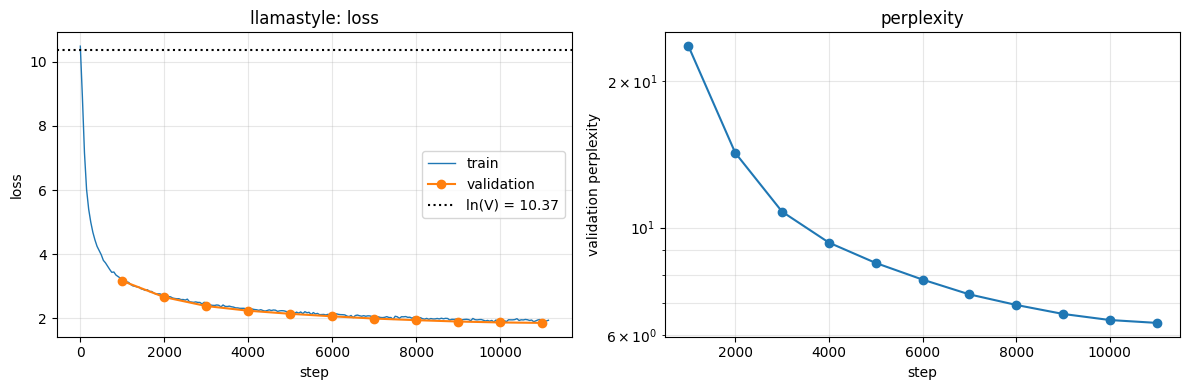

saved: /kaggle/working/phase1_llamastyle/loss_curve.png


In [14]:
import matplotlib.pyplot as plt

tr_s, tr_l, ev_s, ev_l = [], [], [], []
for log in LOG_HISTORY:
    if "loss" in log and "step" in log:
        tr_s.append(log["step"]); tr_l.append(log["loss"])
    if "eval_loss" in log and "step" in log:
        ev_s.append(log["step"]); ev_l.append(log["eval_loss"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tr_s, tr_l, label="train", lw=1)
ax[0].plot(ev_s, ev_l, "o-", label="validation")
ax[0].axhline(LN_VOCAB, ls=":", c="k", label=f"ln(V) = {LN_VOCAB:.2f}")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title(f"{ARCH_NAME}: loss")
if ev_l:
    ax[1].plot(ev_s, [math.exp(min(v, 20)) for v in ev_l], "o-")
    ax[1].set_yscale("log")
ax[1].set_xlabel("step"); ax[1].set_ylabel("validation perplexity")
ax[1].set_title("perplexity"); ax[1].grid(alpha=.3, which="both")
plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=150); plt.show()
print("saved:", LOSS_PLOT_PATH)

## 10. Save the final model


In [15]:
os.makedirs(FINAL_DIR, exist_ok=True)
torch.save(model.state_dict(), os.path.join(FINAL_DIR, "model.pt"))
json.dump({"model_class": type(model).__name__, "arch": ARCH_NAME, "config": asdict(config)},
          open(os.path.join(FINAL_DIR, "config.json"), "w"), indent=2)
tokenizer.save_pretrained(FINAL_DIR)
shutil.copy(os.path.join(DATA_DIR, "bpe_tokenizer.py"), FINAL_DIR)   # self-contained for later phases
json.dump({"arch": ARCH_NAME, "params": n_params, "steps": done_steps,
           "tokens_seen": seen_tokens, "eval_loss": eval_loss, "perplexity": perplexity,
           "train_hours": train_seconds/3600},
          open(os.path.join(FINAL_DIR, "run_summary.json"), "w"), indent=2)
print("saved to", FINAL_DIR, "->", sorted(os.listdir(FINAL_DIR)))

if HUB_ENABLED:
    try:
        upload_folder(repo_id=HUB_MODEL_ID, folder_path=FINAL_DIR, path_in_repo="final",
                      token=HF_WRITE_TOKEN, commit_message=f"final {ARCH_NAME} @ {done_steps} steps")
        print("pushed to", HUB_MODEL_ID, "/final")
    except Exception as e:
        print("hub push failed (local copy is safe):", e)

# Reload later (phases 2+), no transformers needed:
#   cfg = json.load(open(f"{FINAL_DIR}/config.json"))
#   model = <ModelClass>(<ConfigClass>(**cfg["config"])); model.load_state_dict(torch.load(f"{FINAL_DIR}/model.pt"))

saved to /kaggle/working/phase1_llamastyle/final -> ['bpe_model.json', 'bpe_tokenizer.py', 'config.json', 'model.pt', 'run_summary.json', 'tokenizer_config.json']


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

pushed to rudra5972/legal-lm-phase1-llamastyle /final


## 11. Generation

Our own `model.generate` (section 6a), with KV cache. What this cell gets right:

- **left padding** + position ids from the attention mask, so every row in a batch is
  generated exactly as if it were alone (verified by the tests in section 6);
- **left truncation** — a prompt longer than the budget loses its beginning, since the
  continuation follows its end;
- **prompt + output stay inside positions the model was trained on** (`GEN_CONTEXT`);
- `<|endoftext|>`, `<|pad|>`, `<|unk|>` are **suppressed**, so a continuation never stops at a
  document boundary after 30 words — references are always 128 words;
- generation **stops early** once every row has more than 128 words, then each row is cut to 128;
- only the new tokens are returned, so the prompt can't be echoed.

In [16]:
model.eval()
PROMPT_TOKEN_BUDGET = GEN_CONTEXT - MAX_GENERATION_TOKENS
SUPPRESS_IDS = (tokenizer.eos_token_id, tokenizer.pad_token_id, tokenizer.unk_token_id)

def _enough_words(new_tokens, target=TARGET_GENERATION_WORDS):
    return all(len(tokenizer.decode(r, skip_special_tokens=True).split()) > target for r in new_tokens)

@torch.inference_mode()
def generate_batch(prompts, gen_kwargs, target_words=TARGET_GENERATION_WORDS):
    enc = tokenizer(prompts, return_tensors="pt", padding=True,
                    truncation=True, max_length=PROMPT_TOKEN_BUDGET)
    ids, am = enc["input_ids"].to(device), enc["attention_mask"].to(device)
    with amp_ctx():
        new = model.generate(ids, attention_mask=am, max_new_tokens=MAX_GENERATION_TOKENS,
                             suppress_token_ids=SUPPRESS_IDS, stop_fn=_enough_words, **gen_kwargs)
    return [" ".join(tokenizer.decode(r, skip_special_tokens=True).split()[:target_words]) for r in new]

def generate_all(prompts, gen_kwargs, bs=GENERATION_BATCH_SIZE, verbose=True):
    if gen_kwargs.get("num_beams", 1) > 1:
        bs = max(1, bs // gen_kwargs["num_beams"])
    res = []
    for s in range(0, len(prompts), bs):
        chunk = prompts[s:s + bs]
        try:
            res += generate_batch(chunk, gen_kwargs)
        except torch.cuda.OutOfMemoryError:                     # retry one prompt at a time
            torch.cuda.empty_cache()
            res += [generate_batch([p], gen_kwargs)[0] for p in chunk]
        if verbose and (s // bs) % 10 == 0:
            print(f"   {min(s+bs, len(prompts))}/{len(prompts)}", flush=True)
    return res

# token budget check on the held-out references
_le = json.load(open(os.path.join(DATA_DIR, "local_eval.json")))
_tpw = np.mean([len(tokenizer.encode(" " + e["reference"])) / len(e["reference"].split()) for e in _le])
_ptok = np.percentile([len(tokenizer.encode(e["prompt"])) for e in _le], 95)
print(f"tokens/word {_tpw:.2f} -> 128 words ~ {128*_tpw:.0f} tokens (cap {MAX_GENERATION_TOKENS}) | "
      f"prompt p95 {_ptok:.0f} tokens (budget {PROMPT_TOKEN_BUDGET}, longer prompts lose their start)")
if 128 * _tpw * 1.1 > MAX_GENERATION_TOKENS:
    print("WARNING: raise MAX_GENERATION_TOKENS -- some outputs may end under 128 words")

_demo = generate_all([_le[0]["prompt"]], dict(do_sample=True, temperature=0.8, top_p=0.95), verbose=False)
print("demo continuation words:", len(_demo[0].split()))
print(_demo[0][:400])

tokens/word 1.25 -> 128 words ~ 160 tokens (cap 288) | prompt p95 778 tokens (budget 736, longer prompts lose their start)
demo continuation words: 128
they apply to the City Civil Court, and to the division of jurisdiction of the City Civil Court, the jurisdiction of the City Civil Court shall lie within the local limits of the City Civil Court to the City Civil Court, and, in the case of a District Judge, the jurisdiction of the City Civil Court shall be deemed to be the only territory of the City Civil Court within the local limits of the City


## 12. Local metrics on the held-out set

These documents were excluded from `train.bin` and `val.bin` in the prep notebook, so
this is a genuine held-out estimate of the Codabench score. Use it instead of spending
submissions to find out.

*`bert-score` loads its own RoBERTa scorer (it uses `transformers` internally). That is the evaluation metric, not part of our model or training.*

In [17]:
local_eval = json.load(open(os.path.join(DATA_DIR, "local_eval.json")))
print(f"{len(local_eval)} local eval pairs")

from collections import Counter

def _lcs_len(a, b):
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b):
            cur = dp[j + 1]
            dp[j + 1] = prev + 1 if x == y else max(dp[j + 1], dp[j])
            prev = cur
    return dp[len(b)]

def rouge_l_f1(pred, ref):
    p, r = pred.split(), ref.split()
    if not p or not r: return 0.0
    l = _lcs_len(p, r)
    if l == 0: return 0.0
    pr, rc = l / len(p), l / len(r)
    return 2 * pr * rc / (pr + rc)

def bleu4(pred, ref):
    p, r = pred.split(), ref.split()
    if not p: return 0.0
    logs = 0.0
    for n in range(1, 5):
        pc = Counter(tuple(p[i:i+n]) for i in range(len(p)-n+1))
        rc = Counter(tuple(r[i:i+n]) for i in range(len(r)-n+1))
        m = sum(min(c, rc[g]) for g, c in pc.items())
        logs += math.log((m + 1) / (max(1, sum(pc.values())) + 1)) / 4
    bp = 1.0 if len(p) > len(r) else math.exp(1 - len(r) / max(1, len(p)))
    return bp * math.exp(logs)

_BS, _BS_FAILED = None, False
def bertscore_f1(preds, refs):
    """Official primary metric. Falls back to None if bert-score can't load offline."""
    global _BS, _BS_FAILED
    if _BS_FAILED:
        return None
    try:
        if _BS is None:
            from bert_score import BERTScorer
            _BS = BERTScorer(lang="en", rescale_with_baseline=False,
                             device="cuda" if torch.cuda.is_available() else "cpu")
        _, _, f1 = _BS.score(preds, refs, verbose=False, batch_size=16)
        return float(f1.mean())
    except Exception as e:
        _BS_FAILED = True
        print("   bertscore unavailable (", type(e).__name__, str(e)[:90],
              ") -- ranking will fall back to ROUGE-L. Check internet is enabled on this "
              "notebook so bert-score can fetch its scoring model.")
        return None

def score_all(preds, refs):
    return {
        "bertscore_f1": bertscore_f1(preds, refs),
        "rougeL_f1": sum(rouge_l_f1(p, r) for p, r in zip(preds, refs)) / len(preds),
        "bleu4": sum(bleu4(p, r) for p, r in zip(preds, refs)) / len(preds),
        "mean_words": sum(len(p.split()) for p in preds) / len(preds),
    }


47 local eval pairs


### Decoding-strategy sweep

Decoding matters as much as the checkpoint for BERTScore, and you only get 40
submissions. This picks the configuration on the local held-out set instead of guessing.


In [18]:
SWEEP = {
    "greedy":              dict(do_sample=False),
    "greedy_rep1.2_nr4":   dict(do_sample=False, repetition_penalty=1.2,
                                no_repeat_ngram_size=4),
    "beam4_norepeat":      dict(do_sample=False, num_beams=4, no_repeat_ngram_size=4,
                                early_stopping=True),
    "sample_t0.7_p0.9":    dict(do_sample=True, temperature=0.7, top_p=0.9),
    "sample_t0.4_p0.95":   dict(do_sample=True, temperature=0.4, top_p=0.95),
    "sample_t0.8_rep1.1":  dict(do_sample=True, temperature=0.8, top_p=0.95,
                                repetition_penalty=1.1),
}

SWEEP_N = min(24, len(local_eval))     # keep the sweep quick
sweep_prompts = [e["prompt"] for e in local_eval[:SWEEP_N]]
sweep_refs = [e["reference"] for e in local_eval[:SWEEP_N]]

sweep_results = {}
for name, kw in SWEEP.items():
    t0 = time.time()
    preds = generate_all(sweep_prompts, kw, verbose=False)
    sweep_results[name] = score_all(preds, sweep_refs)
    sweep_results[name]["seconds"] = time.time() - t0
    sweep_results[name]["sample"] = preds[0][:200]
    s = sweep_results[name]
    bs = f"{s['bertscore_f1']:.4f}" if s["bertscore_f1"] is not None else "n/a"
    print(f"{name:<20} bertscore {bs}  rougeL {s['rougeL_f1']:.4f}  "
          f"bleu4 {s['bleu4']:.4f}  words {s['mean_words']:.0f}  {s['seconds']:.0f}s")

def _rank_key(item):
    s = item[1]
    return (s["bertscore_f1"] if s["bertscore_f1"] is not None else s["rougeL_f1"])

BEST_DECODE_NAME = max(sweep_results.items(), key=_rank_key)[0]
BEST_DECODE = SWEEP[BEST_DECODE_NAME]
print(f"\nbest decoding strategy: {BEST_DECODE_NAME} -> {BEST_DECODE}")

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


greedy               bertscore 0.7933  rougeL 0.1724  bleu4 0.0516  words 123  45s
greedy_rep1.2_nr4    bertscore 0.8231  rougeL 0.1774  bleu4 0.0488  words 128  11s
beam4_norepeat       bertscore 0.8198  rougeL 0.1783  bleu4 0.0573  words 125  42s
sample_t0.7_p0.9     bertscore 0.8180  rougeL 0.1917  bleu4 0.0611  words 128  11s
sample_t0.4_p0.95    bertscore 0.7999  rougeL 0.1748  bleu4 0.0618  words 128  12s
sample_t0.8_rep1.1   bertscore 0.8262  rougeL 0.1895  bleu4 0.0631  words 128  10s

best decoding strategy: sample_t0.8_rep1.1 -> {'do_sample': True, 'temperature': 0.8, 'top_p': 0.95, 'repetition_penalty': 1.1}


In [19]:
# Full local score with the chosen strategy, on every held-out pair.
full_preds = generate_all([e["prompt"] for e in local_eval], BEST_DECODE)
full_refs = [e["reference"] for e in local_eval]
LOCAL_SCORES = score_all(full_preds, full_refs)
LOCAL_SCORES["decoding"] = BEST_DECODE_NAME
LOCAL_SCORES["n_examples"] = len(local_eval)
print(json.dumps(LOCAL_SCORES, indent=2))

json.dump({"arch": ARCH_NAME, "eval_loss": eval_loss, "perplexity": perplexity,
           "local_scores": LOCAL_SCORES, "sweep": sweep_results},
          open(os.path.join(OUTPUT_DIR, "local_report.json"), "w"), indent=2)

print("\n--- reference vs prediction, first example ---")
print("REF :", full_refs[0][:350])
print("PRED:", full_preds[0][:350])


   8/47
{
  "bertscore_f1": 0.8296014666557312,
  "rougeL_f1": 0.19514627659574468,
  "bleu4": 0.061150187182913644,
  "mean_words": 128.0,
  "decoding": "sample_t0.8_rep1.1",
  "n_examples": 47
}

--- reference vs prediction, first example ---
REF : well as outside such limits immediately before the appointed date, shall, on and from the said date, cease to have jurisdiction within the local limits of the City of Bangalore. (5) Nothing in sub-section (4), shall prejudice or affect the continued operation of any notice served, injunction issued, direction given, proceedings taken, decree or ord
PRED: if it were earlier in force, the High Court. (5) The Registrar General may, when specially empowered in this behalf, make rules consistent with this Act, whether they think fit for exercising jurisdiction in relation to the City Civil Court; (c) rules regulating the period of six months referred to in the said provision. Explanation. - In this sect


## 13. Official test set → prediction.json → submission.zip


In [20]:
from huggingface_hub import hf_hub_download

test_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TEST_FILE,
                            repo_type="dataset", token=HF_TOKEN)
with open(test_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("test examples:", len(test_data))

items = list(test_data.items())
_pid, _prec = items[0]
print("first id:", _pid, "| prompt words:", len(_prec["text"].split()),
      "| prompt tokens:", len(tokenizer(_prec["text"])["input_ids"]))


test.json: 0.00B [00:00, ?B/s]

test examples: 1000
first id: 1 | prompt words: 512 | prompt tokens: 626


In [21]:
test_ids = [str(k) for k, _ in items]
test_prompts = [v["text"] for _, v in items]

t0 = time.time()
test_preds = generate_all(test_prompts, BEST_DECODE)
print(f"generated {len(test_preds)} continuations in {(time.time()-t0)/60:.1f} min")

predictions = {i: {"text": p} for i, p in zip(test_ids, test_preds)}

wc = [len(p.split()) for p in test_preds]
print(f"word counts: min {min(wc)}  median {sorted(wc)[len(wc)//2]}  max {max(wc)}")
short = sum(1 for w in wc if w < TARGET_GENERATION_WORDS)
if short:
    print(f"WARNING: {short} predictions are under {TARGET_GENERATION_WORDS} words. "
          f"Raise MAX_GENERATION_TOKENS if this is a large fraction.")
assert all(isinstance(v["text"], str) and v["text"] for v in predictions.values()), "empty prediction"
# guard against the classic mistake: echoing the prompt back
overlap = sum(1 for p, q in zip(test_preds, test_prompts) if p[:80] and p[:80] in q)
print("predictions that echo the prompt:", overlap, "(should be 0)")


   8/1000
   88/1000
   168/1000
   248/1000
   328/1000
   408/1000
   488/1000
   568/1000
   648/1000
   728/1000
   808/1000
   888/1000
   968/1000
generated 1000 continuations in 5.6 min
word counts: min 87  median 128  max 128
predictions that echo the prompt: 0 (should be 0)


In [22]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")     # at the ZIP ROOT, no folder

print("prediction.json :", PREDICTION_PATH, f"({os.path.getsize(PREDICTION_PATH)/1e6:.2f} MB)")
print("submission.zip  :", SUBMISSION_ZIP)
print("zip contents    :", zipfile.ZipFile(SUBMISSION_ZIP).namelist())
print("\nlocal estimate  :", json.dumps(LOCAL_SCORES))


prediction.json : /kaggle/working/phase1_llamastyle/prediction.json (0.77 MB)
submission.zip  : /kaggle/working/phase1_llamastyle/submission.zip
zip contents    : ['prediction.json']

local estimate  : {"bertscore_f1": 0.8296014666557312, "rougeL_f1": 0.19514627659574468, "bleu4": 0.061150187182913644, "mean_words": 128.0, "decoding": "sample_t0.8_rep1.1", "n_examples": 47}


## 14. Submission checklist

- [ ] `HF_USERNAME` set, `HF_WRITE` secret added, Hub repo receiving checkpoints
- [ ] Parameter count printed in section 6 is inside 50M-300M, model tests passed
- [ ] Init loss was close to `ln(V)`, final validation loss well below it
- [ ] Loss curve saved and still descending (or clearly flattened) at the end
- [ ] Local BERTScore / ROUGE-L / BLEU-4 recorded in `local_report.json`
- [ ] `submission.zip` contains `prediction.json` **at the zip root**, no nested folder
- [ ] Download `submission.zip` from the Kaggle output panel and upload it to Codabench

**Run budget:** minimum 4 submissions are mandatory across the phase, max 10/day,
max 40 total. Submit the first model early to validate the format end to end while the
others are still training — a schema mistake found on day one is free, found on Oct 6 it
is not.

**If this session died mid-training:** set `RESUME = True` at the top and rerun. The
loop loads the newest local `checkpoint-*`, or pulls `last-checkpoint/` from
`{HUB_MODEL_ID}`, and continues with optimizer, scheduler, scaler, RNG and data position
intact. Don't change `PER_DEVICE_BATCH`, `GRAD_ACCUM` or `MAX_STEPS` between sessions.